# Inventory Planning Desk - step-by-step project notebook

**Business Analytics Workshop | CookieSensei Labs | Python 3.12**

Work through **what we are doing, why it is useful, how the code works, and what its output means**. The explanations are Markdown cells, and the analysis is in editable Python code cells with saved results. All records are fictional teaching data; monetary values are INR.

Keep this notebook with [inventory.csv](inventory.csv) and [app.py](app.py). The [Markdown companion](EXPLANATION.md) provides a continuous reading version. The source application and data used here match revision `c10a61c36fffdd048b69dd78926e6663bc986fce`.

## Learning route: turn a stock snapshot into a scenario

Learn to translate a planning rule into columns and predict the effect of changing an assumption. Explain the reorder formula's units, distinguish observations from proposals, and trace one record into a KPI, chart, and report. You will also explain why summing Boolean flags counts records and why cost is calculated before aggregation.

**What one row means:** one fictional SKU at one warehouse. There are 180 records representing 60 distinct SKUs, so repeated `sku` values across warehouses are expected. The relevant identity is the pair `sku` plus `warehouse`. Aggregating too early hides where stock is needed. Monetary amounts are INR. The [original app](app.py) implements a deterministic top-up scenario, not an inventory optimization system or a supplier-ordering service.

| Tool | Role in this notebook | What you should learn to explain |
| --- | --- | --- |
| Python and `Path` | Express the rule and locate the file | Which inputs are data and which are scenario assumptions |
| pandas | Preserve row identity, apply formulas, group records, and export results | How intermediate columns make the recommendation auditable |
| Plotly, Matplotlib, and Seaborn | Show value concentration, record relationships, and distributions | Why different charts need different grains and denominators |
| Streamlit | Let a reader choose warehouses, categories, and buffer days | How a control changes the calculation and the displayed answer |

Why pandas? Each product-location record has its own demand, lead time, stock, and cost. Column operations apply a formula to matching rows; grouping summarizes results. For example, costing every suggested quantity with its own unit cost preserves information that would be lost by multiplying total units by an unweighted average cost.

Use this workflow: **identify the record; select the population; set the assumption; derive measures; aggregate; inspect exceptions; communicate the scenario**. Keep observed stock separate from suggested purchases. The threshold is used as both trigger and top-up target in this teaching rule; the file contains no evidence that it minimizes cost or achieves an optimal service level.

## How to work through this notebook

1. Open `TUTORIAL.ipynb` in JupyterLab or VS Code and select the workshop's Python 3.12 environment.
2. Read the question above a code cell, predict the result, then use **Shift+Enter** to run that cell.
3. Run cells from top to bottom. Python variables stay in the kernel's memory; changing an earlier cell requires rerunning the cells that depend on it.
4. Compare the output with the interpretation underneath. Try the checkpoints before moving on.
5. Use **Restart Kernel and Run All Cells** to reproduce the baseline from a clean session. All executable cells here finish without launching a long-running web server.

The first code cell locates this project and configures notebook chart display. It supports starting in the project folder, the workshop folder, or the repository root. It changes only the kernel's working directory; it does not move any files.

The complete Streamlit teaching script later in this notebook is a **reference code block in a Markdown cell**. Copy it into the stated separate `.py` file to launch its browser interface. The runnable `AppTest` section independently inspects the existing `app.py` and demonstrates a filter rerun inside the notebook. These two execution contexts are explained separately.

Saved figure outputs include embedded PNG previews. In a running JupyterLab or VS Code notebook, Plotly can also display interactive figures. A GitHub preview shows the saved notebook and cannot execute Python. Keep the CSV and app beside the notebook when downloading it for execution. Local JupyterLab users can install the notebook interface with `python -m pip install jupyterlab`; the prepared Cloud Lab already supplies it. Analysis package versions are listed in the [workshop setup](../README.md).

In [1]:
from pathlib import Path                  # Represent a folder or filename as a Python object.
import os                                # Change this kernel's working directory when necessary.
import sys                               # Inspect the Python version selected by the kernel.
from IPython.display import display      # Render tables and figures as notebook outputs.
import matplotlib
import plotly.io as pio

# Support opening the notebook from this folder, the workshop, or the repo root.
notebook_start = Path.cwd()
candidate_folders = [
    notebook_start,
    notebook_start / '04_inventory_planning',
    notebook_start / 'business_analytics_workshop' / '04_inventory_planning',
]
PROJECT_DIR = next(
    (folder for folder in candidate_folders
     if (folder / 'inventory.csv').is_file() and (folder / 'app.py').is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Open this notebook with its sibling CSV and app.py in the project folder.')
PROJECT_DIR = PROJECT_DIR.resolve()
os.chdir(PROJECT_DIR)

# Inline figures belong below their code cells; the Plotly renderer is used by JupyterLab/VS Code.
matplotlib.use('module://matplotlib_inline.backend_inline')
pio.renderers.default = 'plotly_mimetype'
print('Project folder:', PROJECT_DIR.name)
print('CSV and app.py found.')
print('Python:', sys.version.split()[0])

Project folder: 04_inventory_planning
CSV and app.py found.
Python: 3.12.14


### Python vocabulary you will use repeatedly

| Code pattern | What it means | Why it appears here |
| --- | --- | --- |
| `name = expression` | Calculate a value and give it a name | Later cells can reuse the result |
| `import pandas as pd` | Import a library with a short alias | `pd.read_csv(...)` calls its CSV reader |
| `frame["column"]` | Select one named column as a Series | Apply a calculation to that measure |
| `frame[mask]` | Keep rows whose Boolean condition is `True` | Define the population being analyzed |
| `.method(...)` | Ask an object to perform an operation | `.sum()`, `.mean()` and `.groupby()` answer different questions |
| `# explanation` | A comment Python does not execute | Describe the purpose of the next operation |
| `f"...{value:.2f}..."` | Put a formatted value into a string | Communicate results without changing the underlying value |

Indentation groups statements inside a `for`, `if`, function or `with` block. Brackets, parentheses and column spelling matter. When a cell fails, read the final error message, inspect the named variable or column, and fix the earliest failed step before continuing.

## 1. What problem are we solving?

An operations team must balance stock availability with money held in products. A warehouse can hold substantial total stock value while one specific item is close to running out. The analysis therefore works at **one SKU in one warehouse**, estimates stock cover and calculates a proposed top-up under a stated rule.

A **SKU** is a stock keeping unit, a product identifier. The same SKU can appear in Delhi, Mumbai and Bengaluru. The pair `(sku, warehouse)` identifies the record. Stock in one location is not assumed to be instantly available in another.

| Field | Meaning and unit |
| --- | --- |
| `sku` | Product identifier |
| `warehouse` | Stock location |
| `category` | Product group |
| `stock_on_hand` | Current units in that location |
| `daily_demand` | Assumed units/day, not a fitted forecast |
| `lead_time_days` | Assumed supplier lead time, in days |
| `safety_stock` | Baseline safety stock, in units |
| `unit_cost` | INR per unit |

The main rule is:

**Threshold = daily demand × (lead time + extra buffer days) + safety stock.**

**Suggested units = maximum of threshold minus current units, and zero.**

The app asks what this rule implies. It does not choose an optimal policy, predict demand from history or place purchase orders. The slider makes an assumption explicit so its quantity and cost consequences can be examined.

Pandas provides tables, Boolean filters, vectorized arithmetic, grouping and exports. Streamlit makes those results usable in a browser. Plotly provides interactive figures; Matplotlib and Seaborn provide distribution and matrix plots. The different tools have separate jobs.

## 2. Load and understand the source

### Step 01 - Import the tools and locate the inventory file

**Question:** What performs each part of the analysis?

In [2]:
from pathlib import Path             # Handle paths without machine-specific directories.
import pandas as pd                  # Read, filter and calculate on tables.
import matplotlib.pyplot as plt      # Create figures and axes.
import seaborn as sns                # Draw distributions and a heatmap.
import plotly.express as px           # Build interactive figures from DataFrames.

DATA_FILE = Path("inventory.csv")     # These notebook cells run in this project folder.
print("CSV found:", DATA_FILE.is_file())
print("pandas version:", pd.__version__)

CSV found: True
pandas version: 2.2.3


**Interpretation and reasoning**

The aliases are short module names. A relative `Path` works because the notebook directory is specified. In a saved script, the original app uses `Path(__file__).resolve().with_name(...)` so the CSV is found beside that script even if the launch directory differs. Pandas does the calculations; it does not itself create the browser app.

### Step 02 - Load the file and inspect five stock records

**Question:** What does one inventory record contain?

In [3]:
frame = pd.read_csv(DATA_FILE)  # Parse CSV text into a DataFrame with named columns.
print("Source rows:", len(frame))
print("Source columns:", len(frame.columns))
print(frame.head(5).to_string(index=False))

Source rows: 180
Source columns: 8
    sku warehouse    category  stock_on_hand  daily_demand  lead_time_days  safety_stock  unit_cost
SKU-001     Delhi Electronics            316            19              12            27       1103
SKU-002     Delhi        Home            310            25               3            19        565
SKU-003     Delhi     Fashion            120             1               8            38       1008
SKU-004     Delhi     Grocery            315            18               5            31       2482
SKU-005     Delhi Electronics            248             5               4            31       2197


### Notebook skill - inspect a table directly

The printed preview above is useful in scripts and text reports. A notebook can also render the DataFrame itself as a table. `head(5)` returns a small view for inspection; it does not replace the full source table. Compare the row labels on the left with any business identifier column.

In [4]:
# Display the same source as a notebook table; keep frame unchanged.
display(frame.head(5))

,sku,warehouse,category,stock_on_hand,daily_demand,lead_time_days,safety_stock,unit_cost
0,SKU-001,Delhi,Electronics,316,19,12,27,1103
1,SKU-002,Delhi,Home,310,25,3,19,565
2,SKU-003,Delhi,Fashion,120,1,8,38,1008
3,SKU-004,Delhi,Grocery,315,18,5,31,2482
4,SKU-005,Delhi,Electronics,248,5,4,31,2197


**Interpretation and reasoning**

One row contains a product at a location, not the product's global stock or one purchase order. The first row describes SKU-001 at Delhi with 316 units, assumed demand of 19 units/day, a 12-day lead time, 27 safety units and unit cost INR 1,103.

### Step 03 - Check data types and the row identity

**Question:** Why are 180 rows not the same as 180 different products?

In [5]:
# A repeated SKU is valid across warehouses; the SKU-warehouse pair identifies a location.
print(frame.dtypes.astype(str).rename("dtype").to_string())
print()
print("SKU-location rows:", len(frame))
print("Distinct SKU codes:", frame["sku"].nunique())
print("Distinct warehouses:", frame["warehouse"].nunique())
print("Repeated SKU-warehouse pairs:", frame.duplicated(["sku", "warehouse"]).sum())
print()
print(frame.groupby("warehouse").size().rename("locations").to_string())

sku               object
warehouse         object
category          object
stock_on_hand      int64
daily_demand       int64
lead_time_days     int64
safety_stock       int64
unit_cost          int64

SKU-location rows: 180
Distinct SKU codes: 60
Distinct warehouses: 3
Repeated SKU-warehouse pairs: 0

warehouse
Bengaluru    60
Delhi        60
Mumbai       60


**Interpretation and reasoning**

There are 60 SKUs, each in three warehouses. Repeated SKU codes are legitimate, while repeated SKU-warehouse pairs require inspection. The uniqueness check here is an added teaching check; the original app reports exact duplicate rows but does not enforce the composite key. Counting records measures SKU locations, whereas `nunique()` counts distinct labels.

### Step 04 - Apply the original loader's structural checks

**Question:** Is the table structurally usable without silently dropping rows?

In [6]:
required_columns = [
    "sku", "warehouse", "category", "stock_on_hand",
    "daily_demand", "lead_time_days", "safety_stock", "unit_cost",
]
numeric_columns = [
    "stock_on_hand", "daily_demand", "lead_time_days", "safety_stock", "unit_cost",
]

if not set(required_columns).issubset(frame.columns):
    raise ValueError("The CSV is missing required columns.")
if frame.empty:
    raise ValueError("The CSV contains no rows.")

for column in numeric_columns:
    # Reject numeric fields containing unparseable text.
    frame[column] = pd.to_numeric(frame[column], errors="raise")

if frame[required_columns].isna().any().any():
    raise ValueError("Fill missing values in the required analysis columns first.")

print("Required-column, nonempty and numeric checks passed.")
print("Missing source cells:", frame.isna().sum().sum())
print("Exact duplicate source rows:", frame.duplicated().sum())

Required-column, nonempty and numeric checks passed.
Missing source cells: 0
Exact duplicate source rows: 0


**Interpretation and reasoning**

The two any() calls reduce missingness first within each column and then across columns. These checks do not remove duplicate records or validate negative numbers, integer quantities or finite values. In the app, specified loading errors become browser messages followed by `st.stop()`, which ends the current run rather than shutting down the server.

### Step 05 - Reproduce the default warehouse and category filters

**Question:** Which observations contribute to the scenario?

In [7]:
selected_warehouses = sorted(frame["warehouse"].unique())
selected_categories = sorted(frame["category"].unique())

filtered = frame.copy()  # Preserve source rows for source-quality reporting.
filtered = filtered[filtered["warehouse"].isin(selected_warehouses)]
filtered = filtered[filtered["category"].isin(selected_categories)]
if filtered.empty:
    raise ValueError("No rows match these selections.")

print("Warehouses:", ", ".join(selected_warehouses))
print("Categories:", ", ".join(selected_categories))
print(f"Selected SKU locations: {len(filtered)} of {len(frame)}")

Warehouses: Bengaluru, Delhi, Mumbai
Categories: Electronics, Fashion, Grocery, Home
Selected SKU locations: 180 of 180


**Interpretation and reasoning**

`isin(...)` produces a Boolean decision for each row. Applying both masks keeps records meeting both conditions. The app's widgets supply these chosen lists. All categories and warehouses are selected initially. There is no date filter because this is a stock snapshot.

## 3. Derive the measures with units and business meaning

Multiplying units/day by days gives units. Multiplying units by INR/unit gives INR. Dividing units by units/day gives days. Those unit checks explain why the following formulas are sensible before considering Python syntax.

Vectorized arithmetic applies each expression to aligned rows. It multiplies each row's demand by that row's lead time, not a grand total of demand by a grand total of lead time.

### Step 06 - Calculate one record by hand in executable code

**Question:** What exactly changes when the extra buffer increases?

In [8]:
one = filtered.iloc[0]  # The first row by position: SKU-001 at Delhi.

point_zero = one["daily_demand"] * one["lead_time_days"] + one["safety_stock"]
point_seven = one["daily_demand"] * (one["lead_time_days"] + 7) + one["safety_stock"]
units_zero = max(point_zero - one["stock_on_hand"], 0)
units_seven = max(point_seven - one["stock_on_hand"], 0)

print(f"Record: {one['sku']} at {one['warehouse']}")
print(f"Stock value: {one['stock_on_hand']} x {one['unit_cost']} = INR {one['stock_on_hand'] * one['unit_cost']:,.0f}")
print(f"Threshold with 0 extra days: {point_zero} units")
print(f"Threshold with 7 extra days: {point_seven} units")
print(f"Suggested units with 0 extra days: {units_zero}")
print(f"Suggested units with 7 extra days: {units_seven}")
print(f"Cost of the 7-day top-up: INR {units_seven * one['unit_cost']:,.0f}")
print(f"Current cover: {one['stock_on_hand'] / one['daily_demand']:.4f} days")

Record: SKU-001 at Delhi
Stock value: 316 x 1103 = INR 348,548
Threshold with 0 extra days: 255 units
Threshold with 7 extra days: 388 units
Suggested units with 0 extra days: 0
Suggested units with 7 extra days: 72
Cost of the 7-day top-up: INR 79,416
Current cover: 16.6316 days


**Interpretation and reasoning**

Baseline safety stock is already measured in units; the extra buffer is measured in days and must first be multiplied by daily demand. At zero buffer, stock exceeds the threshold, so a negative gap becomes zero. At seven days, the threshold rises above stock and the rule suggests 72 units. Current stock value and days cover stay unchanged because neither observed stock nor assumed demand changed.

### Checkpoint: check units before calculating

Why add buffer days to lead-time days before multiplying by daily demand, then add safety stock? Predict which derived columns should change with buffer and which should remain constant.

### Step 07 - Calculate the five derived columns for every selected row

**Question:** How does one row's arithmetic scale to the whole table?

In [9]:
buffer = 0  # Reproduce the source app's default slider value, in extra days.

filtered["reorder_point"] = (
    filtered["daily_demand"] * (filtered["lead_time_days"] + buffer)
    + filtered["safety_stock"]
)
filtered["reorder_units"] = (
    filtered["reorder_point"] - filtered["stock_on_hand"]
).clip(lower=0)  # Do not suggest a negative purchase.

filtered["inventory_value"] = filtered["stock_on_hand"] * filtered["unit_cost"]
filtered["days_cover"] = filtered["stock_on_hand"].div(
    filtered["daily_demand"].replace(0, float("nan"))  # Zero demand makes cover undefined.
)
filtered["needs_reorder"] = filtered["reorder_units"] > 0  # A Boolean flag for each record.

print(
    filtered[["sku", "warehouse", "stock_on_hand", "reorder_point",
              "reorder_units", "days_cover", "needs_reorder"]]
    .head(5).round(2).to_string(index=False)
)

    sku warehouse  stock_on_hand  reorder_point  reorder_units  days_cover  needs_reorder
SKU-001     Delhi            316            255              0       16.63          False
SKU-002     Delhi            310             94              0       12.40          False
SKU-003     Delhi            120             46              0      120.00          False
SKU-004     Delhi            315            121              0       17.50          False
SKU-005     Delhi            248             51              0       49.60          False


**Interpretation and reasoning**

Each `Series` operation applies to matching rows. `clip(lower=0)` implements a top-up-only rule; it does not recommend transfers or stock disposal. The threshold serves as both trigger and target here, whereas more elaborate inventory policies can use separate thresholds and order-up-to targets. No automatic pack-size rounding is applied.

### Step 08 - Calculate stock value and proposed purchase KPIs

**Question:** What does the selected rule propose overall?

In [10]:
stock_value = filtered["inventory_value"].sum()
reorder_locations = int(filtered["needs_reorder"].sum())  # True contributes 1; False contributes 0.
suggested_units = filtered["reorder_units"].sum()
purchase = (filtered["reorder_units"] * filtered["unit_cost"]).sum()

print(f"Stock value: INR {stock_value:,.0f}")
print(f"Locations needing reorder: {reorder_locations}")
print(f"Suggested units: {suggested_units:,.0f}")
print(f"Estimated purchase: INR {purchase:,.0f}")
print(f"Extra safety buffer: {buffer} days")

Stock value: INR 55,448,799
Locations needing reorder: 53
Suggested units: 5,065
Estimated purchase: INR 5,866,261
Extra safety buffer: 0 days


**Interpretation and reasoning**

Cost each row's proposed quantity before adding, because products have different costs. Multiplying total units by an unweighted mean cost would generally be wrong. Current stock value is a cost valuation, not retail revenue or available cash. Estimated purchase excludes shipping, discounts and other procurement constraints; no order is placed.

### Step 09 - Separate stockouts from replenishment flags

**Question:** Why can replenishment be suggested when no location is out of stock?

In [11]:
# Zero stock is a current condition; a positive top-up flags stock below the scenario threshold.
stockouts = int((filtered["stock_on_hand"] == 0).sum())
positive_stock_reorders = int(
    ((filtered["stock_on_hand"] > 0) & filtered["needs_reorder"]).sum()
)

print("Current zero-stock locations:", stockouts)
print("Locations below the chosen threshold:", reorder_locations)
print("Flagged locations that still have positive stock:", positive_stock_reorders)

Current zero-stock locations: 0
Locations below the chosen threshold: 53
Flagged locations that still have positive stock: 53


**Interpretation and reasoning**

Zero stock and stock below a lead-time threshold are different conditions. The file has no zero-stock records, yet the rule flags 53 locations for replenishment before they necessarily reach zero. The flag is not a probability of stockout.

### Step 10 - Locate current stock value and calculate warehouse shares

**Question:** Where is the cost value of inventory concentrated?

In [12]:
def ratio(numerator, denominator):
    # Same scalar fallback as the source app; a zero denominator is still undefined analytically.
    return numerator / denominator if denominator else 0.0

value_by_warehouse = filtered.groupby("warehouse")["inventory_value"].sum()
warehouse_table = value_by_warehouse.rename("stock_value").to_frame()
warehouse_table["share_pct"] = warehouse_table["stock_value"] / stock_value * 100

print(warehouse_table.round(2).to_string())
top_warehouse = value_by_warehouse.idxmax()  # Obtain the label of the maximum.
print()
print("Largest stock-value total:", top_warehouse)
print(f"Share of selected value: {ratio(value_by_warehouse[top_warehouse], stock_value):.2%}")

           stock_value  share_pct
warehouse                        
Bengaluru     19865405      35.83
Delhi         17190670      31.00
Mumbai        18392724      33.17

Largest stock-value total: Bengaluru
Share of selected value: 35.83%


**Interpretation and reasoning**

Group labels become the result's index, so `idxmax` returns a warehouse name. The share divides its value by the selected total, using comparable INR units. A higher cost value does not prove excess stock: demand, unit prices and lead times also matter. If all value were zero, the helper's fallback would avoid an error but would not make a mathematical share defined.

### Step 11 - Build the same positive-quantity replenishment worklist

**Question:** Which exact records explain the proposed top-up?

In [13]:
# Keep only flagged rows, show their inputs and gap, and rank by proposed quantity.
worklist = filtered.loc[
    filtered["needs_reorder"],
    ["sku", "warehouse", "stock_on_hand", "reorder_point", "reorder_units"],
].sort_values("reorder_units", ascending=False)

print("Total worklist rows:", len(worklist))
print(worklist.head(8).to_string(index=False))

Total worklist rows: 53
    sku warehouse  stock_on_hand  reorder_point  reorder_units
SKU-051    Mumbai             65            360            295
SKU-031     Delhi             21            294            273
SKU-059 Bengaluru             57            301            244
SKU-001    Mumbai             49            269            220
SKU-050    Mumbai              4            220            216
SKU-010 Bengaluru            109            324            215
SKU-049    Mumbai             58            265            207
SKU-006 Bengaluru            117            294            177


**Interpretation and reasoning**

`loc` selects the True rows and listed columns. Sorting descending places the largest proposed quantity first. This is a row-level worklist, not grouped totals or a ranking by urgency. Equality to the threshold gives zero proposed units and is excluded. The full app's largest-row lookup has no explicit secondary tie-break rule, so tied SKUs are not guaranteed an alphabetical winner.

### Checkpoint: predict a scenario comparison

With fixed selected records, can a higher nonnegative buffer reduce suggested units? Can flagged records increase while stock value stays fixed? Explain `clip(lower=0)` before inspecting the scenario table.

### Step 12 - Compare four buffer scenarios on the identical selected records

**Question:** What quantity and cost tradeoff does the buffer imply?

In [14]:
scenarios = []
for extra_days in [0, 3, 7, 14]:
    # Temporary Series keep the baseline filtered table unchanged.
    scenario_point = (
        filtered["daily_demand"] * (filtered["lead_time_days"] + extra_days)
        + filtered["safety_stock"]
    )
    scenario_units = (scenario_point - filtered["stock_on_hand"]).clip(lower=0)
    scenarios.append({
        "extra_days": extra_days,
        "flagged_locations": int((scenario_units > 0).sum()),
        "suggested_units": int(scenario_units.sum()),
        "estimated_purchase": float((scenario_units * filtered["unit_cost"]).sum()),
    })

scenario_table = pd.DataFrame(scenarios)
scenario_table["extra_cost_vs_zero"] = (
    scenario_table["estimated_purchase"] - scenario_table.loc[0, "estimated_purchase"]
)
print(scenario_table.to_string(
    index=False,
    formatters={
        "estimated_purchase": "{:,.2f}".format,
        "extra_cost_vs_zero": "{:,.2f}".format,
    },
))
print()
print("Main tutorial buffer remains:", buffer)

 extra_days  flagged_locations  suggested_units estimated_purchase extra_cost_vs_zero
          0                 53             5065       5,866,261.00               0.00
          3                 69             8043       9,800,855.00       3,934,594.00
          7                 87            12996      16,314,861.00      10,448,600.00
         14                112            24486      31,040,854.00      25,174,593.00

Main tutorial buffer remains: 0


**Interpretation and reasoning**

This four-scenario table is a teaching comparison; the app shows the chosen scenario and compares its cost with a zero-buffer baseline on the same selected records. Extra cost is not necessarily a straight line in days because a well-stocked location contributes zero until its threshold crosses current stock. With the bundled nonnegative inputs, a higher buffer cannot reduce suggested units. These are modeled consequences, not purchase recommendations.

### Step 13 - Compare quantity ranking with cost ranking

**Question:** Is the largest number of units necessarily the largest spending proposal?

In [15]:
# Explicit extension: the shipped worklist ranks quantity, not proposed spending.
ranked = filtered.assign(
    proposed_cost=filtered["reorder_units"] * filtered["unit_cost"]
)
print("Largest quantities:")
print(
    ranked.sort_values("reorder_units", ascending=False)
    [["sku", "warehouse", "reorder_units", "unit_cost", "proposed_cost"]]
    .head(3).to_string(index=False)
)
print()
print("Largest proposed costs:")
print(
    ranked.sort_values("proposed_cost", ascending=False)
    [["sku", "warehouse", "reorder_units", "unit_cost", "proposed_cost"]]
    .head(3).to_string(index=False)
)

Largest quantities:
    sku warehouse  reorder_units  unit_cost  proposed_cost
SKU-051    Mumbai            295       1528         450760
SKU-031     Delhi            273        680         185640
SKU-059 Bengaluru            244       1862         454328

Largest proposed costs:
    sku warehouse  reorder_units  unit_cost  proposed_cost
SKU-059 Bengaluru            244       1862         454328
SKU-051    Mumbai            295       1528         450760
SKU-050    Mumbai            216       1538         332208


**Interpretation and reasoning**

The extra `proposed_cost` column multiplies quantity by each product's cost. The two rankings can differ, so a quantity-ranked worklist must not be described as a cash-priority ranking. Neither ranking incorporates customer commitments, inbound stock or shortage cost.

## 4. Draw the five existing chart types

The figures below are generated from the default zero-extra-buffer selection. Plotly images are static exports of interactive figures; hover and zoom remain available in a live notebook or Streamlit app. Presentation labels make the units explicit without changing the underlying calculations.

### Step 14 - Plot warehouse value and category composition

**Question:** Which warehouses and categories hold most cost value?

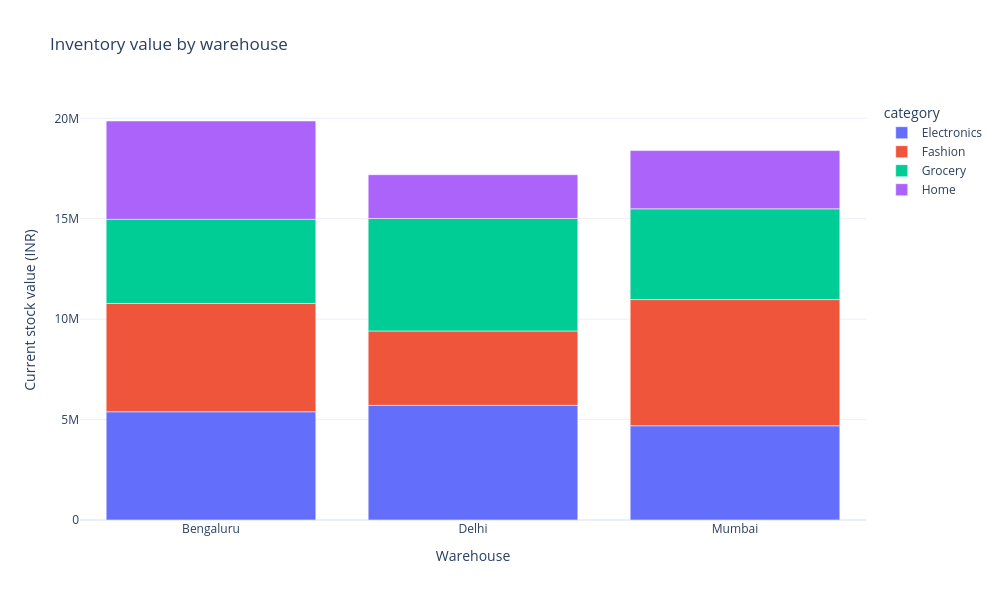

In [16]:
grouped = filtered.groupby(
    ["warehouse", "category"], as_index=False,
)["inventory_value"].sum()  # One total per warehouse/category pair.

fig = px.bar(
    grouped, x="warehouse", y="inventory_value", color="category",
    title="Inventory value by warehouse",
    labels={"inventory_value": "Current stock value (INR)", "warehouse": "Warehouse"},
)
fig.update_layout(template="plotly_white")
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

Each category is a stacked segment, and total bar height is warehouse value. Grouping before plotting avoids treating each individual stock row as a separate regional total. This chart stays unchanged when only the buffer changes, because that parameter does not change current stock or unit cost.

### Step 15 - Plot demand and stock with scenario-dependent flags

**Question:** Which individual locations combine demand and stock levels that trigger the rule?

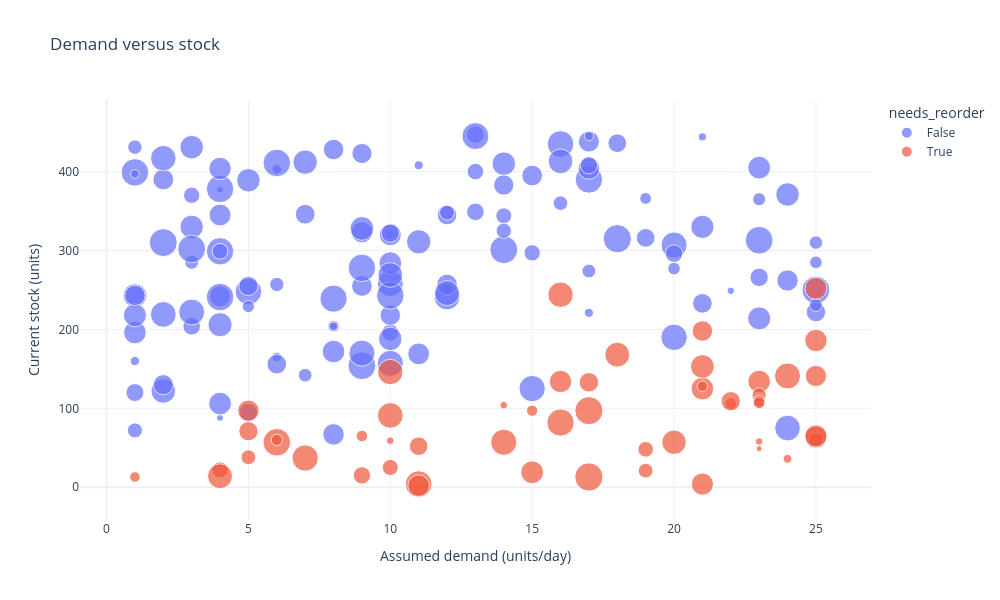

In [17]:
# Each point is a SKU location; color uses the rule flag while size uses unit cost.
fig = px.scatter(
    filtered, x="daily_demand", y="stock_on_hand",
    color="needs_reorder", size="unit_cost",
    hover_data=["sku", "warehouse", "reorder_point"],
    title="Demand versus stock",
    labels={"daily_demand": "Assumed demand (units/day)", "stock_on_hand": "Current stock (units)"},
)
fig.update_layout(template="plotly_white")
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

One point is one SKU-location pair. Bubble size encodes unit cost, not current total value or proposed spending. A buffer change can alter color without moving the point's coordinates. There is no universal threshold line because lead times and baseline safety stock differ across records, and the color is not a probabilistic forecast.

### Step 16 - Inspect the distribution of stock cover

**Question:** Are coverage levels similar, or are some locations much longer or shorter?

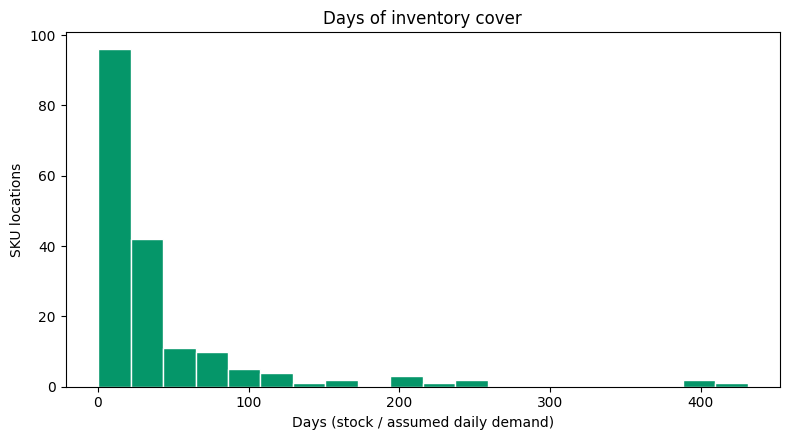

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(
    filtered["days_cover"].dropna(),  # Skip undefined cover, not the whole source records.
    bins=20, color="#059669", edgecolor="white",
)
ax.set(
    title="Days of inventory cover",
    xlabel="Days (stock / assumed daily demand)",
    ylabel="SKU locations",
)
fig.tight_layout()
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

Each location contributes one observation regardless of quantity or cost. For this finite dataset, bin boundaries depend on the selected cover values. Long cover does not automatically mean waste: demand assumptions and replenishment lead times need investigation. A zero-demand record would have undefined cover and be excluded from this histogram while remaining available for other calculations.

### Step 17 - Compare coverage spread across product categories

**Question:** Do categories have different typical cover or different variability?

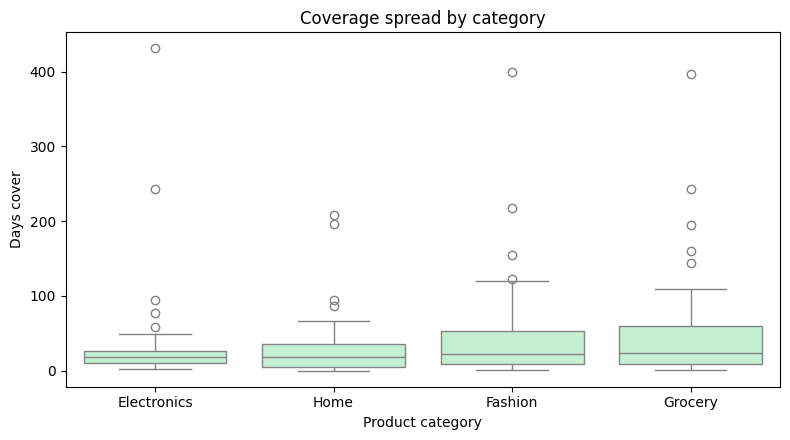

In [19]:
# Compare individual days-cover distributions within each product category.
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(
    data=filtered, x="category", y="days_cover",
    ax=ax, color="#bbf7d0",
)
ax.set(
    title="Coverage spread by category",
    xlabel="Product category", ylabel="Days cover",
)
fig.tight_layout()
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

The line is median cover, the box is the middle 50%, and default whiskers reach observations within 1.5 interquartile ranges of the box. Separate points are prompts to inspect the underlying demand and stock, not instructions to delete rows. Cover assumes constant demand and may be justified differently by category.

### Checkpoint: name the heatmap denominator

Does one warehouse-category cell measure flagged records, proposed units, or money? Name its denominator. Explain why the strongest color need not identify the most expensive group to replenish.

### Step 18 - Visualize the share of locations needing reorder

**Question:** In which warehouse/category cells is review workload widespread?

category   Electronics  Fashion  Grocery   Home
warehouse                                      
Bengaluru        26.67    26.67    33.33  26.67
Delhi            26.67    20.00    33.33  40.00
Mumbai           20.00    33.33    20.00  46.67


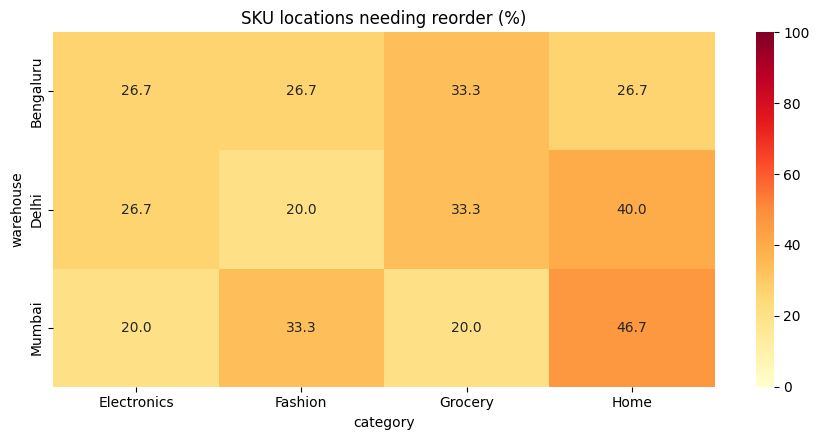

In [20]:
reorder_pct = filtered.pivot_table(
    index="warehouse",
    columns="category",
    values="needs_reorder",
    aggfunc="mean",  # True is 1 and False is 0, so mean is a proportion.
) * 100

print(reorder_pct.round(2).to_string())
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(
    reorder_pct, annot=True, fmt=".1f",
    cmap="YlOrRd", vmin=0, vmax=100, ax=ax,
)
ax.set_title("SKU locations needing reorder (%)")
fig.tight_layout()
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

A cell counts locations equally; it does not measure the share of units, cash or customer impact. Fixed 0-100 bounds keep color meanings consistent across buffer scenarios. Use the worklist and proposed-cost figures alongside the percentages. No observations in a cell would mean missing evidence, not a measured zero requirement.

### Step 19 - Expose the heatmap denominators

**Question:** How many records produced a percentage such as 46.7%?

In [21]:
# Recover group sizes so every reorder percentage can be interpreted with its denominator.
cell_counts = filtered.groupby(["warehouse", "category"]).size().unstack("category")
print(cell_counts.to_string())
print()

example = filtered[
    (filtered["warehouse"] == "Mumbai") & (filtered["category"] == "Home")
]
print("Mumbai/Home locations:", len(example))
print("Mumbai/Home flagged:", int(example["needs_reorder"].sum()))
print(f"Mumbai/Home share: {example['needs_reorder'].mean():.1%}")

category   Electronics  Fashion  Grocery  Home
warehouse                                     
Bengaluru           15       15       15    15
Delhi               15       15       15    15
Mumbai              15       15       15    15

Mumbai/Home locations: 15
Mumbai/Home flagged: 7
Mumbai/Home share: 46.7%


**Interpretation and reasoning**

The bundled cells each contain 15 locations. Mumbai/Home has seven flagged records, giving 7/15. Equal group size is a property of this teaching file, not a guarantee for future data. This denominator table is an added teaching check; the shipped inventory heatmap does not display it as a separate table.

## 5. Verify a focused decision and build its explanation

The remaining analysis cells show how the selected records can be inspected, described and exported. The focused scenario uses a separate table so the baseline calculations above stay reproducible.

### Step 20 - Inspect one warehouse and category under a seven-day scenario

**Question:** Can a manager reproduce the rule for a precisely specified scope?

In [22]:
# Use a separate table for this focused investigation so the tutorial baseline is preserved.
focus = frame[
    frame["warehouse"].isin(["Delhi"])
    & frame["category"].isin(["Electronics"])
].copy()
focus_buffer = 7
focus["reorder_point"] = (
    focus["daily_demand"] * (focus["lead_time_days"] + focus_buffer)
    + focus["safety_stock"]
)
focus["reorder_units"] = (focus["reorder_point"] - focus["stock_on_hand"]).clip(lower=0)

print("Selection: Delhi; Electronics; 7 extra days")
print("Locations:", len(focus))
print("Flagged:", int((focus["reorder_units"] > 0).sum()))
print("Suggested units:", int(focus["reorder_units"].sum()))
print(f"Estimated purchase: INR {(focus['reorder_units'] * focus['unit_cost']).sum():,.2f}")
print(f"Baseline tutorial remains {len(filtered)} locations and {buffer} extra days.")

Selection: Delhi; Electronics; 7 extra days
Locations: 15
Flagged: 7
Suggested units: 1057
Estimated purchase: INR 1,530,571.00
Baseline tutorial remains 180 locations and 0 extra days.


**Interpretation and reasoning**

The scope includes warehouse, category and buffer. Omitting the buffer from a shared result would leave out a material assumption. The separate `focus` variable prevents this investigation from silently changing the baseline charts or exports.

### Step 21 - Inspect numeric summaries and distinguish source from derived quality

**Question:** Which numerical values and ranges lie behind the charts?

In [23]:
# Summarize numeric fields, then compare original missing cells with undefined derived cover.
summary = filtered.select_dtypes(include="number").describe().round(2)
print(summary.to_string())
print()
print("Missing cells in original source:", frame.isna().sum().sum())
print("Undefined derived cover values:", filtered["days_cover"].isna().sum())

       stock_on_hand  daily_demand  lead_time_days  safety_stock  unit_cost  reorder_point  reorder_units  inventory_value  days_cover
count         180.00        180.00          180.00        180.00     180.00         180.00         180.00           180.00      180.00
mean          228.44         12.37            8.26         37.17    1326.23         137.93          28.14        308048.88       41.13
std           128.54          7.55            3.95         15.28     699.71          77.56          58.58        249193.79       66.33
min             2.00          1.00            2.00         10.00     109.00          30.00           0.00          2932.00        0.18
25%           119.25          5.75            5.00         22.75     704.50          73.25           0.00         96725.75        8.75
50%           241.00         11.00            8.50         37.50    1363.50         121.50           0.00        267189.00       20.39
75%           328.50         19.00           12.00     

**Interpretation and reasoning**

The numeric selection excludes the Boolean `needs_reorder` flag; its True count is already shown in a KPI. `describe()` gives counts, averages, sample standard deviations, quartiles and extrema. The original source-quality display uses `frame`, so an edited zero-demand row could create missing derived cover even while source missing-cell count remained zero.

### Checkpoint: verify the report's comparison

The Delhi/Electronics example used a separate selection. Identify which objects still represent the baseline. Incremental cost must compare the current and zero-extra-buffer scenarios for identical selected records.

### Step 22 - Build scope and answer sentences from calculated values

**Question:** How does the app connect a business question with its measured answer?

In [24]:
scope_parts = []
for column in frame.select_dtypes(include="object").columns:
    if frame[column].nunique() <= 12:  # Avoid listing all 60 SKU identifiers.
        values = ", ".join(map(str, sorted(filtered[column].unique())))
        scope_parts.append(column.replace("_", " ") + ": " + values)
scope = "; ".join(scope_parts) + f"; extra safety buffer: {buffer} days"

insights = [
    (
        "What stock is represented?",
        f"{len(filtered)} SKU locations, {filtered['sku'].nunique()} distinct SKUs, "
        f"INR {stock_value:,.2f} at cost.",
    ),
    (
        "What top-up does the rule suggest?",
        f"{suggested_units:,.0f} units across {reorder_locations} locations, "
        f"estimated cost INR {purchase:,.2f}.",
    ),
    ("How many locations have zero stock?", str(stockouts)),
]
print("Scope:", scope)
for question, answer in insights:
    print(question)
    print(answer)

Scope: warehouse: Bengaluru, Delhi, Mumbai; category: Electronics, Fashion, Grocery, Home; extra safety buffer: 0 days
What stock is represented?
180 SKU locations, 60 distinct SKUs, INR 55,448,799.00 at cost.
What top-up does the rule suggest?
5,065 units across 53 locations, estimated cost INR 5,866,261.00.
How many locations have zero stock?
0


**Interpretation and reasoning**

The text comes from variables and f-strings, not an external AI model. Low-cardinality text fields describe the selection, and the buffer is explicitly appended. These sentences distinguish location counts from unique SKUs, current value from proposed cost, and zero stock from a reorder flag.

### Step 23 - Create a compact Markdown report from the same results

**Question:** How can an analysis become a readable file without duplicating calculations?

In [25]:
# This is a small teaching reconstruction; the original app assembles twelve sections.
kpi_values = [
    ("Stock value", f"INR {stock_value:,.2f}"),
    ("Locations flagged", str(reorder_locations)),
    ("Suggested units", f"{suggested_units:,.0f}"),
    ("Estimated purchase", f"INR {purchase:,.2f}"),
    ("Extra buffer days", str(buffer)),
]
report_parts = [
    "# Inventory - tutorial report",
    "## Scope\n" + scope,
    "## Results\n| Measure | Value |\n| --- | --- |\n"
    + "\n".join(f"| {name} | {value} |" for name, value in kpi_values),
    "## Questions\n"
    + "\n\n".join(f"### {question}\n{answer}" for question, answer in insights),
    "## Limit\nDemand and lead time are assumed fixed. Incoming orders are not modeled. No purchase is placed.",
]
teaching_report = "\n\n".join(report_parts)
print(teaching_report)

# Inventory - tutorial report

## Scope
warehouse: Bengaluru, Delhi, Mumbai; category: Electronics, Fashion, Grocery, Home; extra safety buffer: 0 days

## Results
| Measure | Value |
| --- | --- |
| Stock value | INR 55,448,799.00 |
| Locations flagged | 53 |
| Suggested units | 5,065 |
| Estimated purchase | INR 5,866,261.00 |
| Extra buffer days | 0 |

## Questions
### What stock is represented?
180 SKU locations, 60 distinct SKUs, INR 55,448,799.00 at cost.

### What top-up does the rule suggest?
5,065 units across 53 locations, estimated cost INR 5,866,261.00.

### How many locations have zero stock?
0

## Limit
Demand and lead time are assumed fixed. Incoming orders are not modeled. No purchase is placed.


**Interpretation and reasoning**

`join` combines strings in a deliberate order, and each f-string inserts current values. One report string can be displayed and offered as a download. In the original app, `report_parts[5]` is the KPI section because the report title occupies index 0; that is where its field dictionary is appended. The full report additionally describes methods, five visuals, source quality and limits.

### Step 24 - Preview the analytical CSV download

**Question:** Which evidence is available behind a shared scenario?

In [26]:
csv_text = filtered.to_csv(index=False)  # Include fields, not the pandas row index.
print("\n".join(csv_text.splitlines()[:4]))
print()
print("Exported data rows:", len(csv_text.splitlines()) - 1)
print("Exported columns:", ", ".join(filtered.columns))

sku,warehouse,category,stock_on_hand,daily_demand,lead_time_days,safety_stock,unit_cost,reorder_point,reorder_units,inventory_value,days_cover,needs_reorder
SKU-001,Delhi,Electronics,316,19,12,27,1103,255,0,348548,16.63157894736842,False
SKU-002,Delhi,Home,310,25,3,19,565,94,0,175150,12.4,False
SKU-003,Delhi,Fashion,120,1,8,38,1008,46,0,120960,120.0,False

Exported data rows: 180
Exported columns: sku, warehouse, category, stock_on_hand, daily_demand, lead_time_days, safety_stock, unit_cost, reorder_point, reorder_units, inventory_value, days_cover, needs_reorder


**Interpretation and reasoning**

The CSV includes the source fields plus all five derived columns for the selected buffer. This cell creates a string; it does not overwrite inventory.csv. The app provides that string through a download button. A downloaded result does not automatically add the proposed units to current stock.

### Step 25 - Demonstrate zero-demand handling on a separate practice copy

**Question:** Are undefined cover and a fallback percentage the same thing?

In [27]:
# Intentionally modify a copy, not the source CSV or the baseline filtered table.
zero_example = frame.head(2).copy()
zero_example.loc[zero_example.index[0], "daily_demand"] = 0

zero_example["days_cover"] = zero_example["stock_on_hand"].div(
    zero_example["daily_demand"].replace(0, float("nan"))
)
zero_example["inventory_value"] = zero_example["stock_on_hand"] * zero_example["unit_cost"]
zero_point = (
    zero_example["daily_demand"] * zero_example["lead_time_days"]
    + zero_example["safety_stock"]
)
zero_example["needs_reorder"] = (zero_point - zero_example["stock_on_hand"]).clip(lower=0) > 0

print(
    zero_example[["sku", "stock_on_hand", "daily_demand",
                  "days_cover", "inventory_value", "needs_reorder"]]
    .round(2).to_string(index=False)
)
print("Defined cover values:", zero_example["days_cover"].dropna().size)
print("Scalar ratio(10, 0) fallback:", ratio(10, 0))
print("Zero-demand rows in the unchanged source:", int((frame["daily_demand"] == 0).sum()))

    sku  stock_on_hand  daily_demand  days_cover  inventory_value  needs_reorder
SKU-001            316             0         NaN           348548          False
SKU-002            310            25        12.4           175150          False
Defined cover values: 1
Scalar ratio(10, 0) fallback: 0.0
Zero-demand rows in the unchanged source: 0


**Interpretation and reasoning**

They use different mechanisms. Zero demand becomes NaN before cover division, and the histogram drops that missing cover. The record still has stock value and a threshold based on safety stock. The scalar ratio helper instead returns 0.0 for a zero denominator to prevent an error; that fallback is not a mathematical definition of an undefined ratio.

### Step 26 - Add explicit domain checks as a separate improvement

**Question:** What else should be checked before using a new inventory file?

In [28]:
# These business-domain checks are additional to the original app's numeric parsing checks.
domain_checks = pd.Series({
    "SKU-warehouse pairs are unique": not frame.duplicated(["sku", "warehouse"]).any(),
    "Stock is nonnegative": frame["stock_on_hand"].ge(0).all(),
    "Demand is nonnegative": frame["daily_demand"].ge(0).all(),
    "Lead time is nonnegative": frame["lead_time_days"].ge(0).all(),
    "Safety stock is nonnegative": frame["safety_stock"].ge(0).all(),
    "Unit cost is nonnegative": frame["unit_cost"].ge(0).all(),
    "Stock units are whole numbers": frame["stock_on_hand"].mod(1).eq(0).all(),
})
print(domain_checks.to_string())

SKU-warehouse pairs are unique    True
Stock is nonnegative              True
Demand is nonnegative             True
Lead time is nonnegative          True
Safety stock is nonnegative       True
Unit cost is nonnegative          True
Stock units are whole numbers     True


**Interpretation and reasoning**

These additional checks pass for the bundled file but are not all enforced by the original loader. Negative demand can break expected scenario behavior; negative cost can make spending meaningless and conflict with marker-size plotting. Finite values, pack sizes, valid categories and accuracy need additional checks too. The original app does not round proposed quantities to case packs merely because its cards show zero decimal places.

## 6. Assemble a complete Streamlit teaching app

The Streamlit reference script below runs separately from this notebook, independent of the notebook namespace. Copy only its Python code into `practice_inventory_app.py` beside `inventory.csv` and run:

```bash
streamlit run practice_inventory_app.py
```

Use `--server.port 8502` for a separate instance when the workshop dashboard already uses port 8501, and open the forwarded port.

This compact reconstruction includes the scenario slider, filters, four KPIs, five charts, positive-gap worklist, record export and a short report. The original `app.py` additionally contains the complete business narrative, field dictionary, per-chart guides and twelve-section report.


### Step 27 - Build the interactive inventory planning interface

## From notebook calculations to an interactive planning screen

In the [original `app.py`](app.py), Warehouses and Categories multiselects successively filter `frame` into `filtered`. The Extra safety buffer slider supplies `buffer`, from 0 to 14 days. These controls answer two different questions: **which records are included**, and **which planning assumption is applied**. Separate them when comparing results.

| Analysis measure or object | Original app destination | Why this connection matters |
| --- | --- | --- |
| `inventory_value`, `needs_reorder`, `reorder_units`, and `purchase` | Four KPI cards | Current stock value, flagged-record count, proposed units, and proposed cost are distinct quantities |
| `base_reorder` and `base_purchase` | Incremental-cost finding | The zero-extra-buffer baseline uses the same selected records |
| Warehouse/category value totals | Stacked Plotly bar | Aggregation answers where money is held at cost |
| Individual SKU-location records | Demand/stock scatter | Each point is one stock record; color is the reorder flag and size is unit cost |
| `days_cover` | Histogram and category boxplot | These show the distribution of coverage, not a purchase recommendation |
| Mean of `needs_reorder` within warehouse/category | Reorder heatmap | The Boolean mean becomes a proportion of records after multiplying by 100 |
| Positive `reorder_units` records | Reorder worklist | The rows retain SKU-location identity and are ranked by suggested quantity |
| `scope`, `insights`, and `full_report` | Findings and downloadable report | The text records the current selections and buffer |

Notebook variables persist between executions. After editing a filter or `buffer`, rerun derivations and dependent cells. A Streamlit widget change reruns the script in order. Uncached loading picks up CSV changes on the next rerun. An empty result calls `st.stop()` for that execution, without stopping the server. Hover, table sorting, and tab switching do not filter the analysis; all tabs compute during a Streamlit 1.50 run.

The complete Streamlit script is a Markdown reference to save separately and launch with `streamlit run`. Executable `AppTest` cells inspect the sibling `app.py` and change widgets; notebook variables are not injected into it. The original adds a twelve-section report. Neither submits purchase orders. The quantity-sorted worklist does not establish a priority based on cost, stockout timing, supplier constraints, or business importance.

### Complete Streamlit teaching script - reference

The following complete script is shown in a **Markdown reference cell**. It is intended for the separate `.py` file described above, because Streamlit renders controls and pages through its own server execution. The analysis cells in this notebook have already calculated and explained the measures used here.

```python
from pathlib import Path
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st

st.set_page_config(page_title="Inventory planning - tutorial", layout="wide")
st.title("Inventory planning - tutorial")
st.caption("Fictional SKU-location snapshot; amounts are INR.")

data_file = Path(__file__).resolve().with_name("inventory.csv")
required = [
    "sku", "warehouse", "category", "stock_on_hand",
    "daily_demand", "lead_time_days", "safety_stock", "unit_cost",
]
numeric = ["stock_on_hand", "daily_demand", "lead_time_days", "safety_stock", "unit_cost"]
try:
    frame = pd.read_csv(data_file)
    if not set(required).issubset(frame.columns) or frame.empty:
        raise ValueError("Supply a nonempty CSV with the required columns.")
    for column in numeric:
        frame[column] = pd.to_numeric(frame[column], errors="raise")
    if frame[required].isna().any().any():
        raise ValueError("Fill missing required values.")
except (OSError, ValueError, KeyError) as error:
    st.error(str(error))
    st.stop()  # End this run while keeping the app available for correction.

warehouses = st.sidebar.multiselect(
    "Warehouses", sorted(frame["warehouse"].unique()),
    default=sorted(frame["warehouse"].unique()), key="inventory_demo_warehouses",
)
categories = st.sidebar.multiselect(
    "Categories", sorted(frame["category"].unique()),
    default=sorted(frame["category"].unique()), key="inventory_demo_categories",
)
filtered = frame[
    frame["warehouse"].isin(warehouses) & frame["category"].isin(categories)
].copy()
if filtered.empty:
    st.info("Select at least one warehouse and category with matching records.")
    st.stop()

# This scalar widget value participates in every row's threshold formula.
buffer = st.sidebar.slider("Extra safety buffer (days)", 0, 14, 0, key="inventory_demo_buffer")
filtered["reorder_point"] = (
    filtered["daily_demand"] * (filtered["lead_time_days"] + buffer) + filtered["safety_stock"]
)
filtered["reorder_units"] = (filtered["reorder_point"] - filtered["stock_on_hand"]).clip(lower=0)
filtered["inventory_value"] = filtered["stock_on_hand"] * filtered["unit_cost"]
filtered["days_cover"] = filtered["stock_on_hand"].div(
    filtered["daily_demand"].replace(0, float("nan"))
)
filtered["needs_reorder"] = filtered["reorder_units"] > 0
purchase = (filtered["reorder_units"] * filtered["unit_cost"]).sum()

cards = st.columns(4)
cards[0].metric("Stock value (INR)", f"{filtered['inventory_value'].sum():,.0f}")
cards[1].metric("Locations needing reorder", f"{filtered['needs_reorder'].sum():,}")
cards[2].metric("Suggested units", f"{filtered['reorder_units'].sum():,.0f}")
cards[3].metric("Estimated purchase (INR)", f"{purchase:,.0f}")

dashboard, explore, data_tab, report_tab = st.tabs(["Dashboard", "Explore", "Data", "Report"])
with dashboard:
    grouped = filtered.groupby(
        ["warehouse", "category"], as_index=False,
    )["inventory_value"].sum()
    st.plotly_chart(
        px.bar(grouped, x="warehouse", y="inventory_value", color="category",
               title="Inventory value by warehouse"),
        use_container_width=True,
    )
    st.plotly_chart(
        px.scatter(filtered, x="daily_demand", y="stock_on_hand",
                   color="needs_reorder", size="unit_cost",
                   hover_data=["sku", "warehouse", "reorder_point"],
                   title="Demand versus stock"),
        use_container_width=True,
    )
    worklist = filtered.loc[
        filtered["needs_reorder"],
        ["sku", "warehouse", "stock_on_hand", "reorder_point", "reorder_units"],
    ].sort_values("reorder_units", ascending=False)
    st.subheader("Replenishment worklist")
    st.dataframe(worklist, hide_index=True, width="stretch")

with explore:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(filtered["days_cover"].dropna(), bins=20, color="#059669", edgecolor="white")
    ax.set(xlabel="Days cover", ylabel="SKU locations")
    st.pyplot(fig)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(data=filtered, x="category", y="days_cover", ax=ax)
    st.pyplot(fig)
    plt.close(fig)

    share = filtered.pivot_table(
        index="warehouse", columns="category", values="needs_reorder", aggfunc="mean",
    ) * 100
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.heatmap(share, annot=True, fmt=".1f", vmin=0, vmax=100, cmap="YlOrRd", ax=ax)
    st.pyplot(fig)
    plt.close(fig)

with data_tab:
    st.dataframe(filtered, hide_index=True, width="stretch")
    st.download_button(
        "Download selected CSV", filtered.to_csv(index=False),
        "tutorial_inventory_selection.csv", "text/csv",
    )

report = (
    "# Inventory scenario summary\n\n"
    f"Selected SKU locations: {len(filtered)}\n\n"
    f"Extra safety days: {buffer}\n\n"
    f"Estimated purchase: INR {purchase:,.2f}\n\n"
    "Demand and lead time are assumed fixed. No purchase is placed."
)
with report_tab:
    st.markdown(report)
    st.download_button("Download short report", report, "tutorial_inventory_report.md", "text/markdown")
```

## Inspect the actual Streamlit application from this notebook

The companion script above is a compact teaching reconstruction. The next executable cells inspect the **existing sibling `app.py`**, which also contains the complete business context, chart explanations and full report.

`AppTest` is Streamlit's testing interface. It runs the application and lets Python inspect the UI elements it produced. It does not start a browser server. We use it here to connect the notebook's calculations with the application's real labels and values. The displayed tables summarize application elements; they are not browser screenshots.

### Load and run the sibling app

`AppTest.from_file(...)` reads a saved Streamlit script; `.run()` executes it with default widget values. The checks stop this cell if the app raises an exception or displays a loading error. Keeping `app.py` beside its CSV lets its `Path(__file__)` lookup work independently of notebook variables.

In [29]:
from streamlit.testing.v1 import AppTest  # Inspect Streamlit output without launching a server.
import logging

# AppTest intentionally runs without a browser session; quiet its context-only warning.
# Application errors are still checked explicitly below.
logging.getLogger('streamlit.runtime.scriptrunner_utils.script_run_context').setLevel(logging.ERROR)

app_file = PROJECT_DIR / 'app.py'
app_preview = AppTest.from_file(str(app_file), default_timeout=45).run()
if len(app_preview.exception):
    raise RuntimeError('; '.join(str(error.value) for error in app_preview.exception))
if len(app_preview.error):
    raise RuntimeError('; '.join(str(error.value) for error in app_preview.error))

print('Script:', app_file.name)
print('Title:', app_preview.title[0].value)
print('Default application run completed.')

Script: app.py
Title: Inventory Planning Desk
Default application run completed.


### Read the controls, KPI cards and output containers

The values below come from the application instance that just ran. A metric element has a `label` and a formatted `value`; a multiselect has the current list of choices. The table dimensions describe what the app actually rendered. Chart counts distinguish interactive Plotly figures from Matplotlib/Seaborn images.

In [30]:
# Turn rendered KPI cards into an ordinary table we can inspect in the notebook.
baseline_cards = {metric.label: metric.value for metric in app_preview.metric}
display(pd.DataFrame(baseline_cards.items(), columns=['Dashboard measure', 'Displayed value']))

for widget in app_preview.multiselect:
    print(widget.label + ': ' + ', '.join(map(str, widget.value)))
for widget in app_preview.date_input:
    print(widget.label + ': ' + ' to '.join(map(str, widget.value)))
for widget in app_preview.slider:
    print(widget.label + ': ' + str(widget.value))
for index, table in enumerate(app_preview.dataframe, start=1):
    print(f'Table {index}: {len(table.value)} rows x {len(table.value.columns)} columns')
print('Interactive Plotly charts:', len(app_preview.get('plotly_chart')))
print('Rendered statistical charts:', len(app_preview.get('imgs')))
for button in app_preview.get('download_button'):
    print('Download:', button.proto.label)

,Dashboard measure,Displayed value
0,Stock value (INR),"55,448,799"
1,Locations needing reorder,53
2,Suggested units,"5,065"
3,Estimated purchase (INR),"5,866,261"


Warehouses: Bengaluru, Delhi, Mumbai
Categories: Electronics, Fashion, Grocery, Home
Extra safety buffer (days): 0
Table 1: 5 rows x 3 columns
Table 2: 53 rows x 5 columns
Table 3: 8 rows x 2 columns
Table 4: 180 rows x 13 columns
Table 5: 8 rows x 9 columns
Table 6: 8 rows x 3 columns
Interactive Plotly charts: 2
Rendered statistical charts: 3
Download: Download filtered CSV
Download: Download full report (Markdown)


### Change one filter and observe a real app rerun

This cell selects one value in the first multiselect and compares the resulting KPI cards with the baseline. `.set_value(...)` changes the control; `.run()` executes the app again. We then restore the complete selection so the preview ends in its default state.

The notebook's own `frame` and `filtered` variables belong to the analysis session. `AppTest` executes the script in its own application context, so changing this preview does not silently alter the earlier notebook analysis. In the live browser app, the corresponding widget interaction triggers the rerun for you.

In [31]:
# Keep all original choices so the application can be restored after this experiment.
first_control = app_preview.multiselect[0]
original_choices = list(first_control.value)
one_choice = original_choices[0]
control_label = first_control.label

# This is the programmatic equivalent of narrowing a sidebar multiselect.
first_control.set_value([one_choice]).run()
if len(app_preview.exception) or len(app_preview.error):
    raise RuntimeError('The narrowed app selection did not complete successfully.')
selected_cards = {metric.label: metric.value for metric in app_preview.metric}
comparison = pd.DataFrame({
    'Dashboard measure': list(baseline_cards),
    'All choices': list(baseline_cards.values()),
    f'{control_label}: {one_choice}': [selected_cards[label] for label in baseline_cards],
})
display(comparison)

# Restore the baseline; the notebook data and the source CSV have not been edited.
app_preview.multiselect[0].set_value(original_choices).run()
if len(app_preview.exception) or len(app_preview.error):
    raise RuntimeError('The application could not restore its original selection.')
print('Restored', control_label + ':', ', '.join(map(str, original_choices)))

,Dashboard measure,All choices,Warehouses: Bengaluru
0,Stock value (INR),"55,448,799","19,865,405"
1,Locations needing reorder,53,17
2,Suggested units,"5,065","1,562"
3,Estimated purchase (INR),"5,866,261","1,903,079"


Restored Warehouses: Bengaluru, Delhi, Mumbai


### Open the browser interface

In a **terminal in this project folder**, run:

```bash
python -m streamlit run app.py --server.port 8502
```

Open the displayed local URL, or forward port 8502 in Cloud Labs. The built-in workshop dashboard uses port 8501. Streamlit keeps running while the page is available; stop it with **Ctrl+C** in that terminal. This command is a terminal instruction, so **Run All** in this notebook does not start the server.

Follow one choice through the app: widget value → pandas row selection → derived columns → grouped results → cards/charts/report. This is the connection between the analysis and its browser interface.

## 7. Relate the tutorial to the original app

The original source stores explanations in `CASE`, `DECISION`, `DATA_CONTEXT`, `FORMULAS`, `VISUAL_GUIDE`, `RECOMMENDATIONS` and `LIMITATIONS`. Its `explain_visual` helper pairs each figure with purpose, reading instructions, a question and a limitation. Those strings explain calculations; they do not make the inventory decisions.

The full source calculates a zero-extra-buffer purchasing baseline for the same filtered records, then reports the incremental cost of the selected buffer. It distinguishes unique SKUs from SKU locations and zero stock from a positive proposed top-up. Its quantity-ranked worklist is row-level despite a generic caption referring to grouped values.

### Current limitations

- Demand is an assumed constant, not a forecast fitted by this app.
- Lead time is fixed, and baseline safety stock is an input rather than an estimated service-level policy.
- Incoming purchase orders, backorders, stock transfers, supplier capacity, expiry, order multiples and procurement discounts are absent.
- The threshold is also used as the proposed top-up target; this is not an optimization of shortage and carrying costs.
- Stock value is current cost value. Purchase cost is hypothetical and does not update stock.
- Source-quality checks use `frame`; derived missing cover belongs to `filtered` and is not counted as a source missing cell.
- The original loader does not enforce nonnegative values, finite numbers, integer units or unique SKU-location keys.
- The warehouse leader uses `idxmax()`, whose ties follow the grouped result order. The largest individual quantity uses `sort_values(...).iloc[0]` without an explicit secondary tie-break rule.
- A higher reorder percentage counts more flagged locations proportionally; it does not necessarily imply more units, spending or urgency.
- Saving a CSV edit is reflected on the next rerun; saving alone does not guarantee an automatic rerun.

### Questions to try next

Change a selection in Step 05 and rerun the later analysis. Explain why SKU and location counts can differ. Set `buffer` in Step 07 to seven and rerun all later cells to reproduce that scenario's charts. Add incoming stock in a practice copy, but state when it is assumed to arrive. Add pack-size rounding only after defining the pack-size field and the intended rule. Compare quantity and cost rankings without calling either an optimal purchasing plan.

## References

The project-specific source is [app.py](app.py), [inventory.csv](inventory.csv) and the [workshop setup](../README.md). All printed results and figures above are generated from the displayed cells.

- [pandas 2.2 introduction](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/10min.html) and [grouping](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/groupby.html)
- [Streamlit execution](https://docs.streamlit.io/develop/concepts/architecture/run-your-app) and [Streamlit 1.50 tabs](https://docs.streamlit.io/1.50.0/develop/api-reference/layout/st.tabs)
- [Plotly Express](https://plotly.com/python/plotly-express/)
- [Seaborn boxplots](https://seaborn.pydata.org/generated/seaborn.boxplot.html)
- [Matplotlib figure cleanup](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.close.html)

## Practice predicting consequences

1. **Change the buffer while preserving the population.** Compare zero and seven extra days. Hint: current stock value and days of cover should stay fixed, while thresholds and suggested purchases can increase. Explain why the purchase-cost increase is not simply seven times a single total: clipping removes negative gaps, and each row has its own cost.
2. **Compare two meanings of “largest.”** Inspect the quantity and cost ranking extension. Hint: a large unit gap for a cheap item can cost less than a smaller gap for an expensive item. Which ranking answers a procurement-budget question? What other evidence would you need before declaring either record most urgent?
3. **Investigate zero demand on a practice copy.** Use the existing zero-demand example without editing the CSV. Hint: `days_cover` becomes missing rather than an infinite or zero-day estimate. The record can still contribute to stock value and other calculations. Explain why the histogram omits it and why a source-wide missing-cell count does not describe derived missing values.

Ask after each experiment: Did the data change, did the selection change, or did only an assumption change? Does a flagged row mean it has no stock, or that stock is below the scenario threshold? Could incoming orders or changing demand alter the recommendation?

Before presenting, explain the SKU-location grain, filter scope, buffer, units, clipping rule, purchase-cost aggregation, and heatmap denominator. Check the execution state. Explain the decision this scenario informs and the information still needed to act.

## Finish with an explanation you can defend

Before presenting the project, explain one complete chain in your own words: **the question, the source rows, the operation, the result, and the decision it informs**. State the units and denominator. Show a supporting table or chart and one limitation. Then restart the kernel and run the notebook from the top to confirm that the result does not depend on forgotten interactive state.

Notebook and application references: [Jupyter notebook structure](https://nbformat.readthedocs.io/en/latest/format_description.html), [Plotly notebook renderers](https://plotly.com/python/renderers/), and [Streamlit 1.50 AppTest](https://docs.streamlit.io/1.50.0/develop/api-reference/app-testing/st.testing.v1.apptest).